# MEDIAL INSURANCE DATASET - KAGGLE

## importing lib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msn
import kagglehub
import os

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression\
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msn
import kagglehub
import os

from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.feature_selection import SequentialFeatureSelector

print("Done setup!")
from sklearn.feature_selection import SequentialFeatureSelector

print("Done setup!")


print("Done setup!")

SyntaxError: invalid syntax (382076984.py, line 14)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mirichoi0218/insurance")

print("Path to dataset files:", path)

Path to dataset files: /home/anuj/.cache/kagglehub/datasets/mirichoi0218/insurance/versions/1


## Data

In [3]:

# 1. Download the dataset using kagglehub
path = kagglehub.dataset_download("mirichoi0218/insurance")
print("Path to dataset files:", path)

# 2. Construct the full file path (kagglehub downloads to a folder, usually containing 'insurance.csv')

csv_file_path = os.path.join(path, "insurance.csv")

# 3. Load the dataset into a pandas DataFrame
df = pd.read_csv(csv_file_path)

# 4. Display the first few rows to verify
df.head()

Path to dataset files: /home/anuj/.cache/kagglehub/datasets/mirichoi0218/insurance/versions/1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### describe data

In [4]:
df.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


### data information 

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


### null value
- No null value detected.

In [6]:
### null value confirmation 
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

<Axes: >

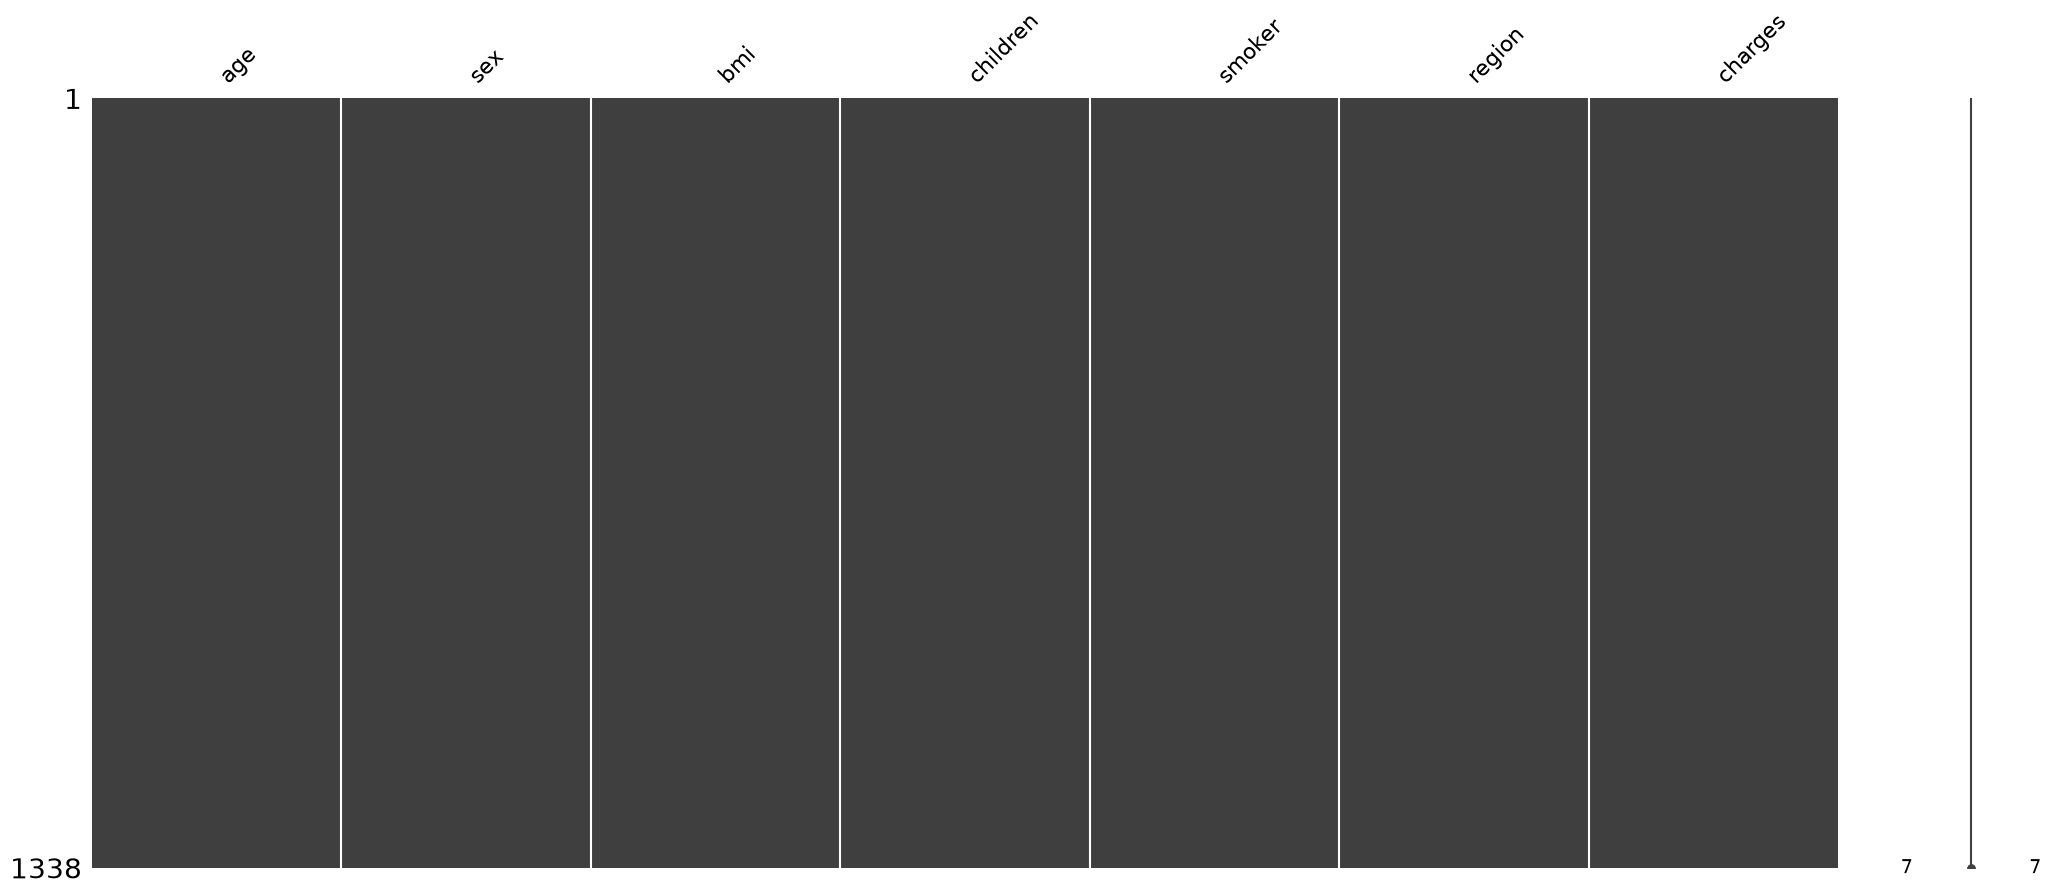

In [7]:
msn.matrix(df)

## correlation with target variable

In [8]:
df.corrwith(df["charges"], numeric_only=True)

age         0.299008
bmi         0.198341
children    0.067998
charges     1.000000
dtype: float64

In [9]:
df.corr(numeric_only = True)

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


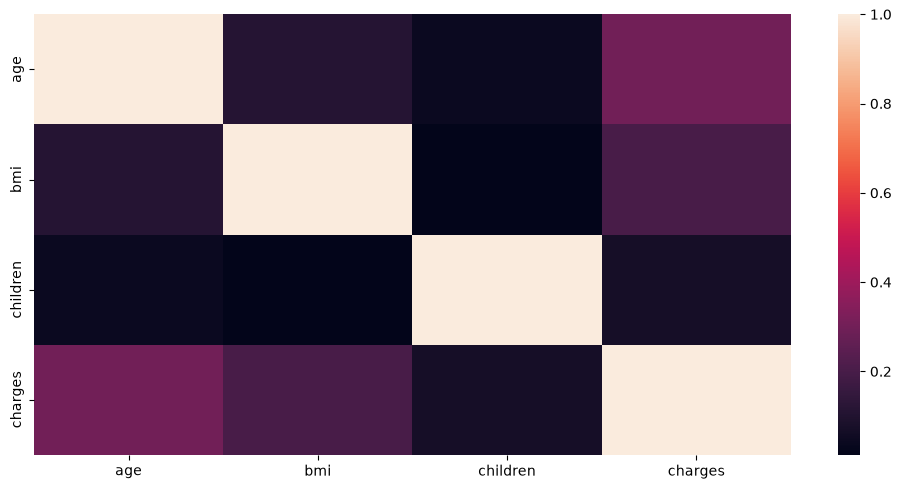

In [10]:
plt.figure(figsize = (10, 5))
sns.heatmap(df.corr(numeric_only = True))
plt.tight_layout()
plt.savefig('Correlation')
plt.show()

### scatter plot

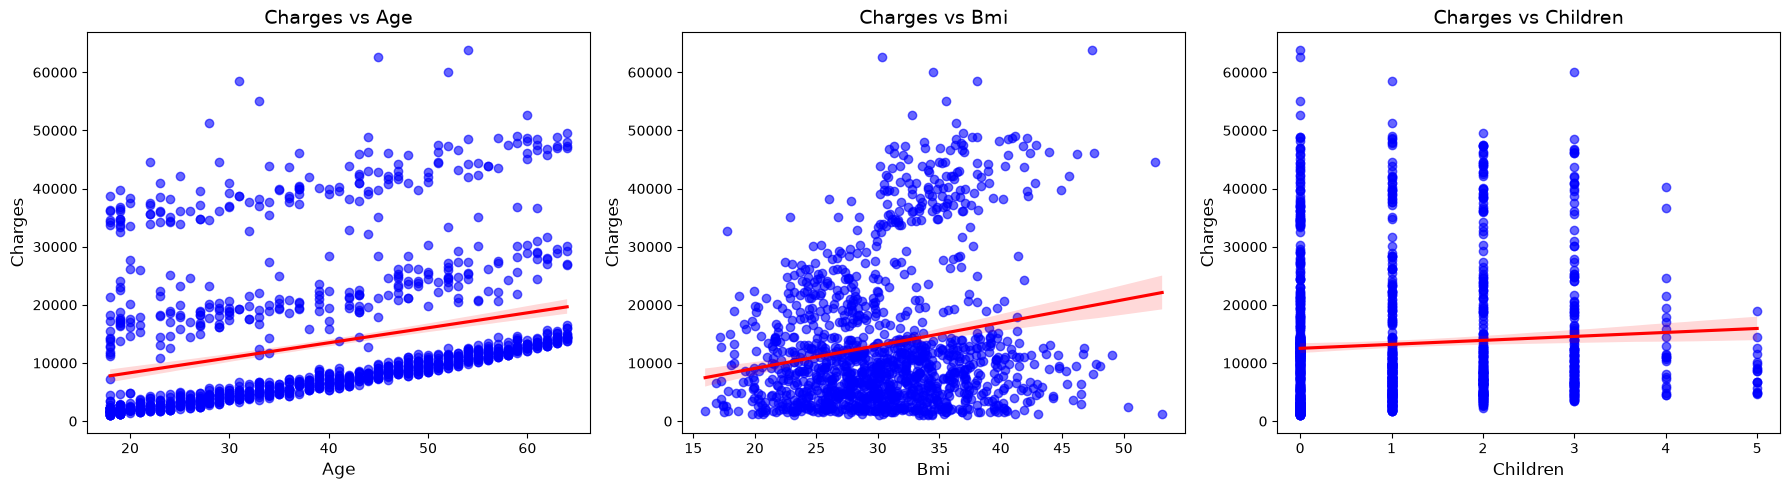

In [11]:

features = ['age', 'bmi', 'children']
target = 'charges'

# Set up the matplotlib figure with subplots side-by-side
fig, axes = plt.subplots(1, len(features), figsize=(18, 5))

# Loop through each feature and create a regplot on its respective subplot
for i, feature in enumerate(features):
    sns.regplot(
        data=df,
        x=feature,
        y=target,
        ax=axes[i],
        scatter_kws={'alpha': 0.6, 'color': 'blue'},
        line_kws={'color': 'red'}
    )
    
    # Add suitable titles and labels
    axes[i].set_title(f'{target.capitalize()} vs {feature.capitalize()}', fontsize=14)
    axes[i].set_xlabel(feature.capitalize(), fontsize=12)
    axes[i].set_ylabel(target.capitalize(), fontsize=12)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.savefig("checking multi-correlarity")
plt.show()

## applying one hot enconding on categorical variable 

In [12]:
# 1. Define the columns you want to one-hot encode (categorical + children)
cols_to_encode = ['sex', 'smoker', 'region', 'children']

# 2. Set up the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(sparse_output=False, drop='first'), cols_to_encode)
    ],
    remainder='passthrough' # Keeps remaining numeric columns (like age, bmi, charges) intact
)

# 3. Fit and transform your DataFrame
encoded_array = preprocessor.fit_transform(df)

# 4. Recreate the DataFrame with proper column names
# Get the new feature names for the encoded columns
encoded_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cols_to_encode)

# Identify the remaining columns that passed through untouched
remaining_cols = [col for col in df.columns if col not in cols_to_encode]

# Combine all column names
all_columns = list(encoded_feature_names) + remaining_cols

# Create the final encoded DataFrame
df_encoded = pd.DataFrame(encoded_array, columns=all_columns)

# Display the first few rows
df_encoded.head()

,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,children_1,children_2,children_3,children_4,children_5,age,bmi,charges
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,19.0,27.900,16884.92400
1,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,18.0,33.770,1725.55230
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,28.0,33.000,4449.46200
3,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.0,22.705,21984.47061
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32.0,28.880,3866.85520


In [13]:
df_encoded.columns

Index(['sex_male', 'smoker_yes', 'region_northwest', 'region_southeast',
       'region_southwest', 'children_1', 'children_2', 'children_3',
       'children_4', 'children_5', 'age', 'bmi', 'charges'],
      dtype='str')

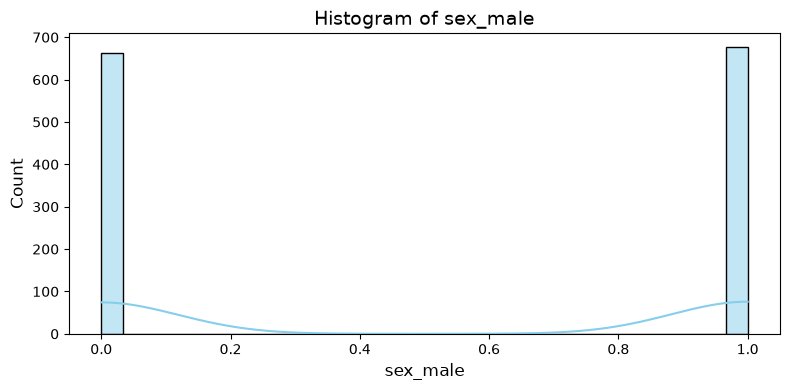

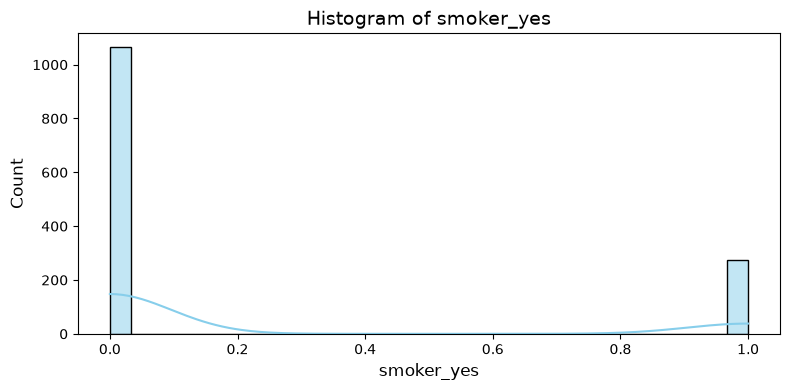

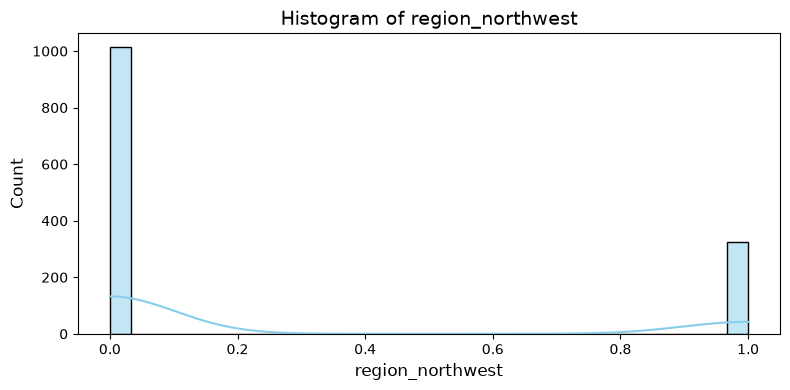

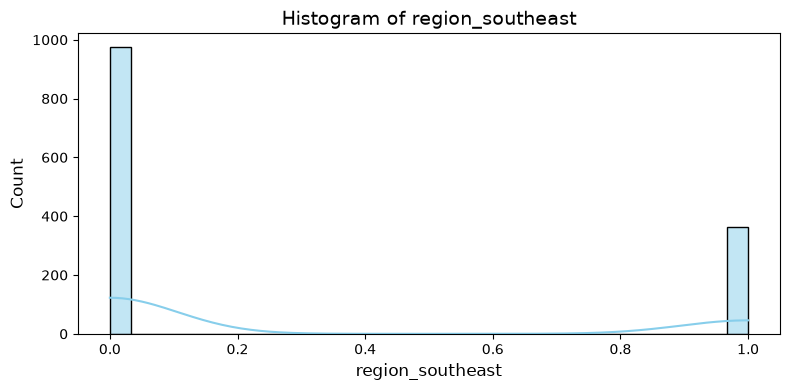

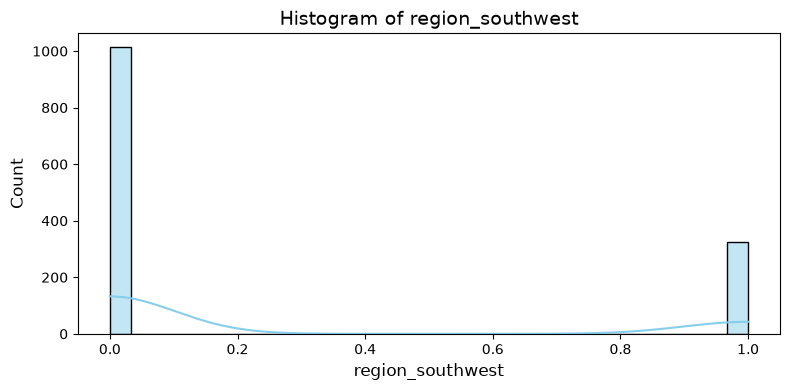

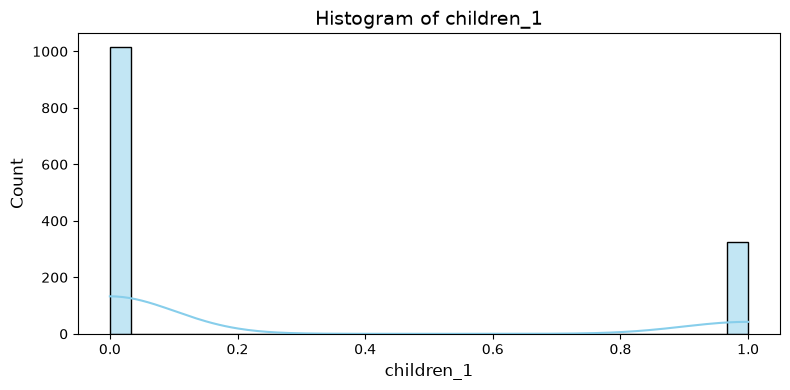

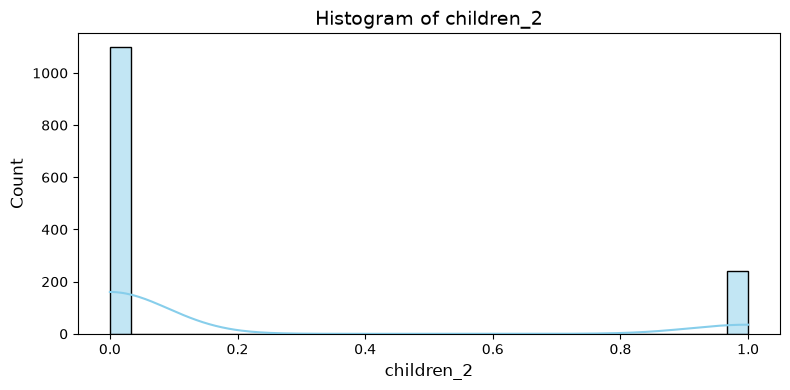

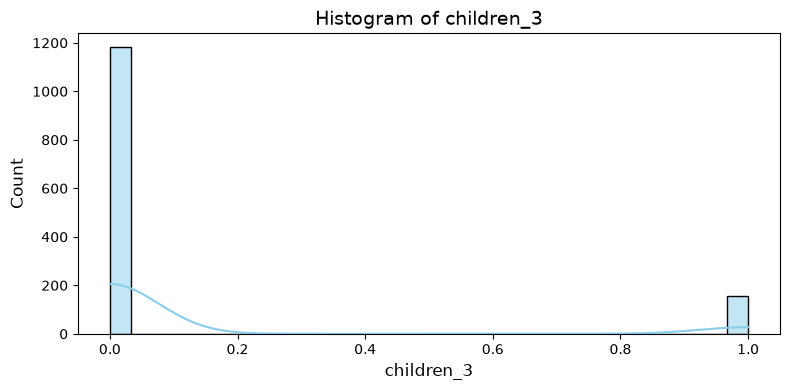

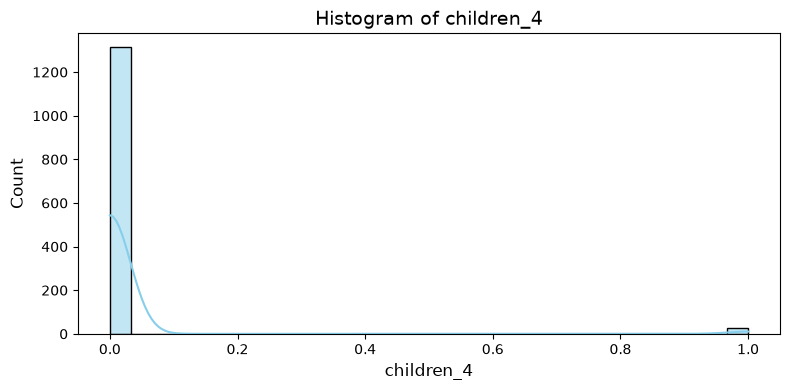

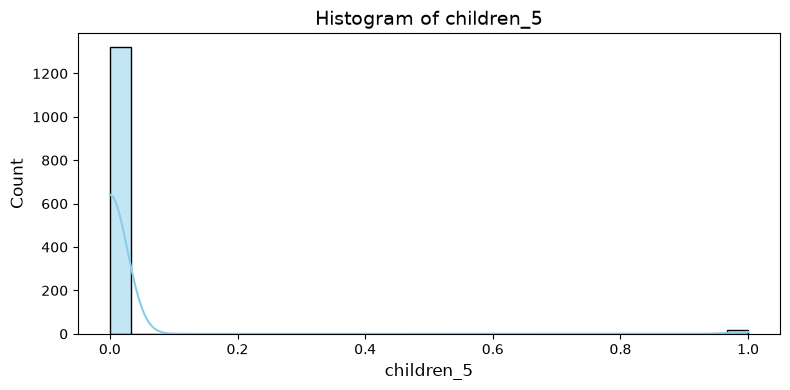

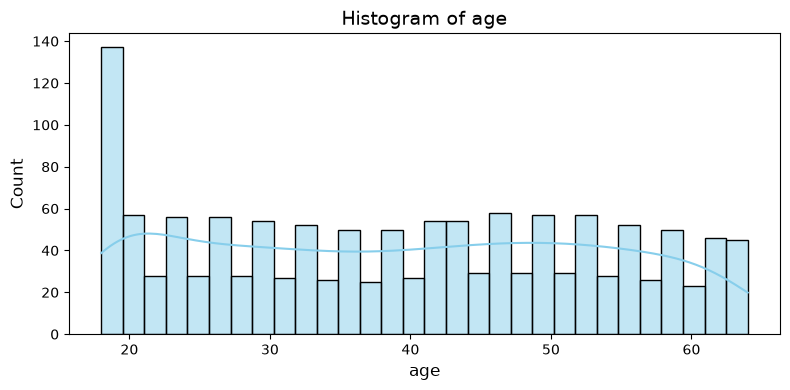

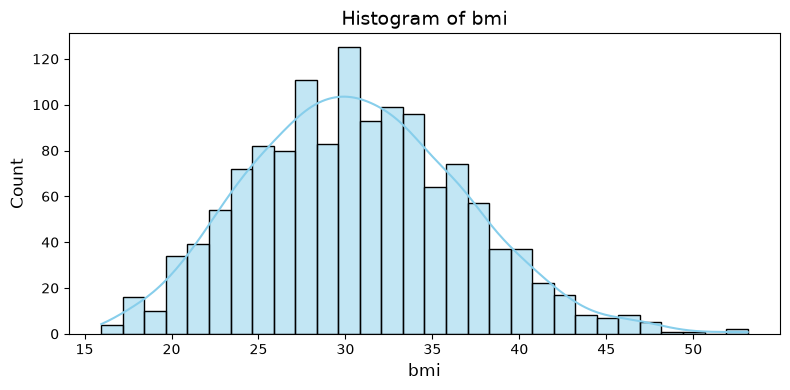

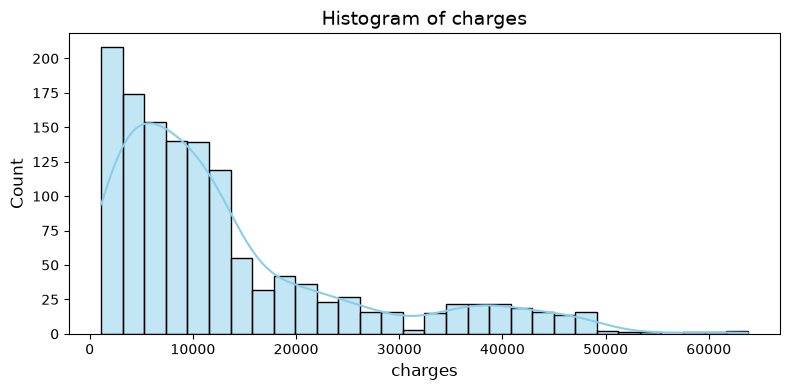

In [14]:

columns_to_plot = [
    'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 
    'region_southwest', 'children_1', 'children_2', 'children_3', 
    'children_4', 'children_5', 'age', 'bmi', 'charges'
]

# Loop through each column and create a separate figure
for col in columns_to_plot:
    plt.figure(figsize=(8, 4))
    
    # Add KDE line for continuous variables like age, bmi, and charges
    use_kde = col in ['age', 'bmi', 'charges']
    
    sns.histplot(
        data=df_encoded, 
        x=col, 
        kde=True, 
        bins=30,
        color='skyblue'
    )
    
    plt.title(f'Histogram of {col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    
    plt.tight_layout()
    plt.show()

## skewness
- no such skewness detected

## outliers

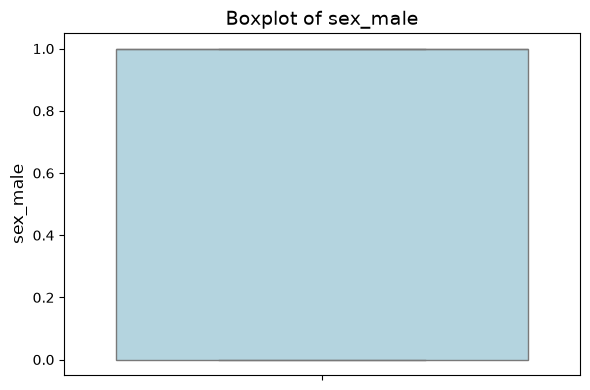

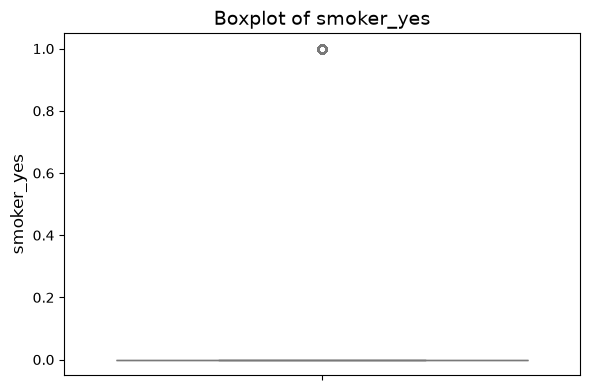

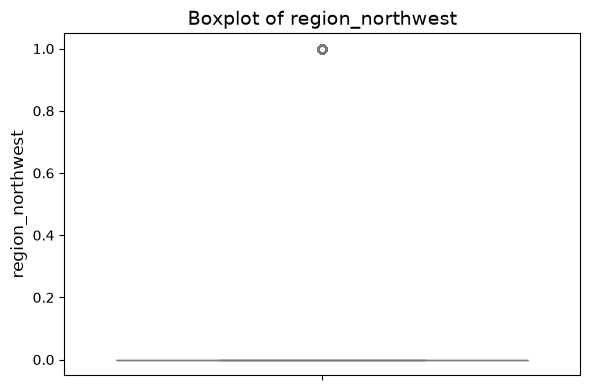

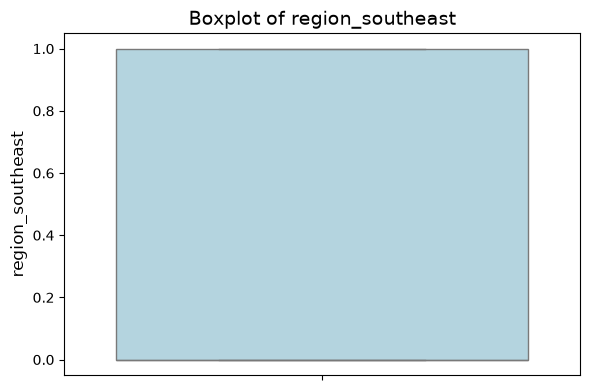

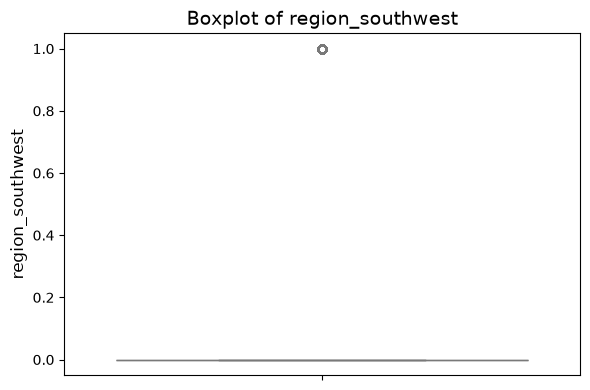

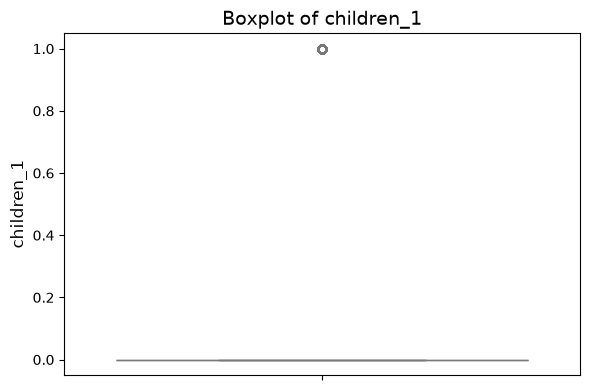

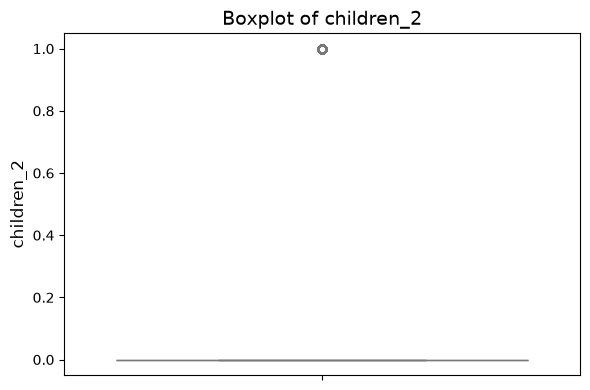

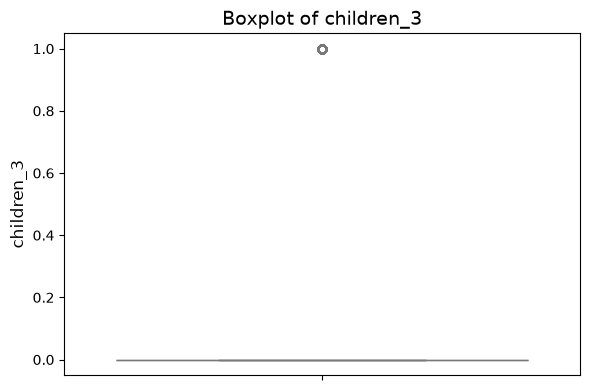

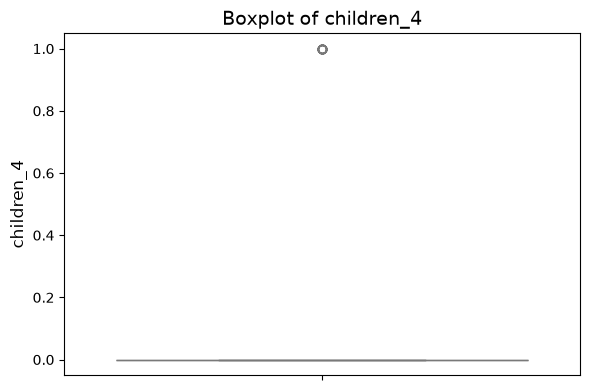

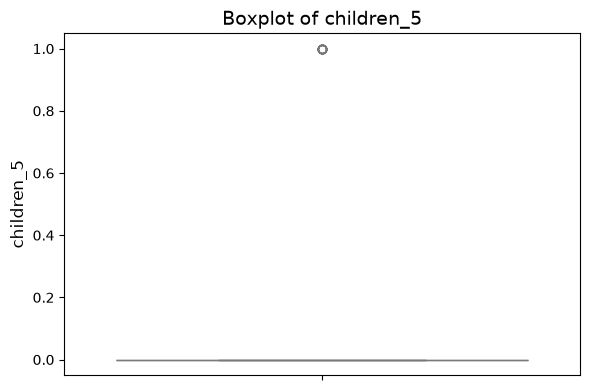

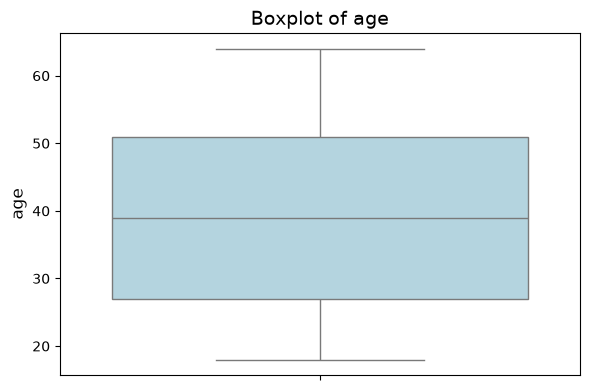

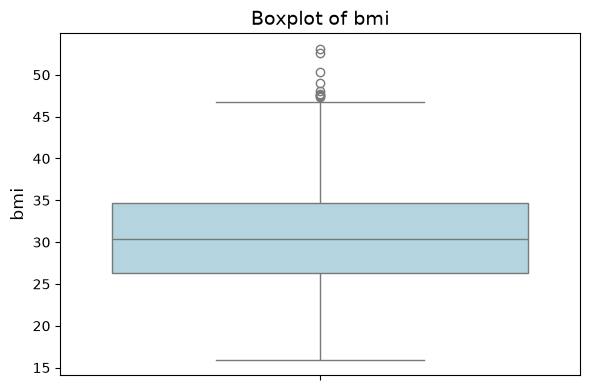

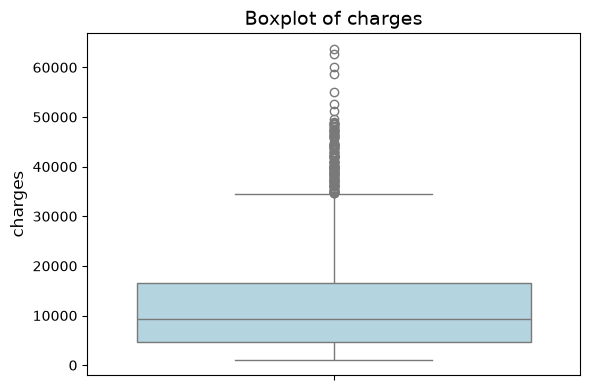

In [15]:
for col in columns_to_plot:
    plt.figure(figsize=(6, 4))
    
    # Use y=col for a vertical boxplot (or x=col for horizontal)
    sns.boxplot(
        data=df_encoded,
        y=col,
        color='lightblue'
    )
    
    plt.title(f'Boxplot of {col}', fontsize=14)
    plt.ylabel(col, fontsize=12)
    
    plt.tight_layout()
    plt.show()

## seperating x and y variables

In [16]:
X = df_encoded.drop(columns =["charges"])
y = df_encoded.charges

## Applying Robust scaler since ages and bmi contains very low outliers

In [17]:
# 1. Define the continuous numeric features you want to scale
numeric_features_to_scale = ['age', 'bmi']

# 2. Set up the ColumnTransformer with RobustScaler
robust_transformer = ColumnTransformer(
    transformers=[
        ('robust', RobustScaler(), numeric_features_to_scale)
    ],
    remainder='passthrough' # Leaves your one-hot encoded columns and target untouched
)

# 3. Fit and transform your DataFrame
scaled_array = robust_transformer.fit_transform(X)

# 4. Convert it back to a clean pandas DataFrame
# Get the updated column order (scaled columns come first, followed by remainder columns)
remainder_cols = [col for col in X.columns if col not in numeric_features_to_scale]
all_columns = numeric_features_to_scale + remainder_cols

X_scaled= pd.DataFrame(scaled_array, columns=all_columns, index=df_encoded.index)

# Display the first few rows
X_scaled.head()

,age,bmi,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,children_1,children_2,children_3,children_4,children_5
0,-0.833333,-0.297708,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,-0.875000,0.401310,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,-0.458333,0.309616,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.250000,-0.916344,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.291667,-0.181006,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## MODEL SELECTION


In [18]:
# Split data for consistency across models
X_scaled_train, X_scaled_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
n = len(X_scaled_train)  # Training sample size for Adjusted R2

def evaluate_model(X_tr, X_te, y_tr, y_te, feature_names):
    p = X_tr.shape[1]  # Number of predictors
    
    # Train model
    model = LinearRegression()
    model.fit(X_tr, y_tr)
    
    # Predictions & R2 on Test Set
    y_pred = model.predict(X_te)
    r2 = r2_score(y_te, y_pred)
    
    # Training R2 for Adjusted R2 calculation
    r2_train = model.score(X_tr, y_tr)
    adj_r2 = 1 - (((1 - r2_train) * (n - 1)) / (n - p - 1))
    
    # Predicted R2 (Cross-Validated R2 using 5 folds)
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')
    pred_r2 = cv_scores.mean()
    
    return {
        "Model Type": feature_names,
        "Num Features": p,
        "R2": r2,
        "Adjusted R2": adj_r2,
        "Predicted R2 (CV)": pred_r2
    }

results = []

# ==========================================
# 1. Simple Linear Regression (1 feature)
# ==========================================
X_simple = X_scaled_train[['bmi']]
X_simple_test = X_scaled_test[['bmi']]
results.append(evaluate_model(X_simple, X_simple_test, y_train, y_test, "Simple (BMI)"))

# ==========================================
# 2. Multiple Linear Regression (2 features)
# ==========================================
X_multi2 = X_scaled_train[['bmi', 'smoker_yes']]
X_multi2_test = X_scaled_test[['bmi', 'smoker_yes']]
results.append(evaluate_model(X_multi2, X_multi2_test, y_train, y_test, "Multiple (2 features)"))

# ==========================================
# 3. Multiple Linear Regression (3 features)
# ==========================================
X_multi3 = X_scaled_train[['bmi', 'smoker_yes', 'age']]
X_multi3_test = X_scaled_test[['bmi', 'smoker_yes', 'age']]
results.append(evaluate_model(X_multi3, X_multi3_test, y_train, y_test, "Multiple (3 features)"))

# ==========================================
# 4. Sequential Feature Selection (SFS)
# ==========================================
# Automatically selects the best 4 features using forward selection
base_model = LinearRegression()
sfs = SequentialFeatureSelector(base_model, n_features_to_select=11, direction='forward', cv=5)
sfs.fit(X_scaled_train, y_train)

# Get selected feature names
selected_features = X_scaled_train.columns[sfs.get_support()].tolist()
print(f"Features selected by Sequential Feature Selector: {selected_features}")

X_sfs_train = X_scaled_train[selected_features]
X_sfs_test = X_scaled_test[selected_features]
results.append(evaluate_model(X_sfs_train, X_sfs_test, y_train, y_test, f"Sequential ({len(selected_features)} features)"))

# ==========================================
# Summary Results Table
# ==========================================
df_results = pd.DataFrame(results)
print("\n--- Model Performance Comparison ---")
print(df_results.to_string(index=False))

NameError: name 'r2_score' is not defined

### model graph

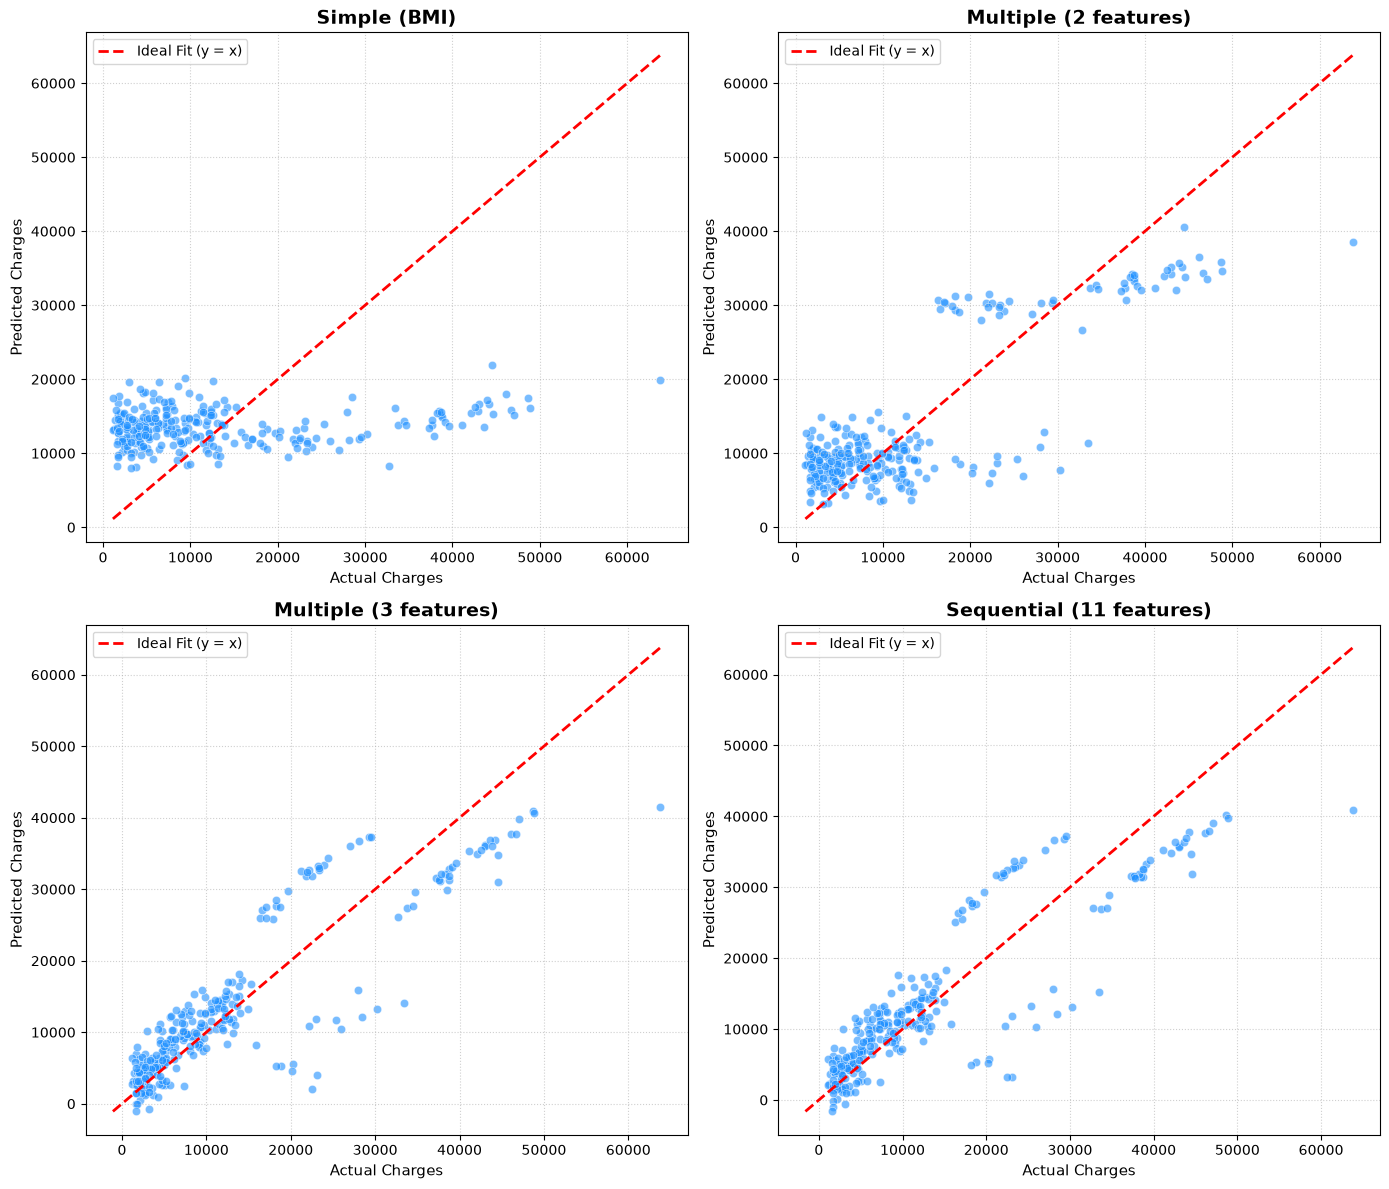

In [ ]:
# 1. Organize all four models using your exact training/testing splits
models_dict = {
    "Simple (BMI)": {
        "X_tr": X_scaled_train[['bmi']],
        "X_te": X_scaled_test[['bmi']]
    },
    "Multiple (2 features)": {
        "X_tr": X_scaled_train[['bmi', 'smoker_yes']],
        "X_te": X_scaled_test[['bmi', 'smoker_yes']]
    },
    "Multiple (3 features)": {
        "X_tr": X_scaled_train[['bmi', 'smoker_yes', 'age']],
        "X_te": X_scaled_test[['bmi', 'smoker_yes', 'age']]
    },
    f"Sequential ({len(selected_features)} features)": {
        "X_tr": X_scaled_train[selected_features],
        "X_te": X_scaled_test[selected_features]
    }
}

# 2. Set up a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

# 3. Iterate, train, predict, and plot each model
for i, (name, data) in enumerate(models_dict.items()):
    # Train the model
    reg = LinearRegression()
    reg.fit(data["X_tr"], y_train)
    y_pred = reg.predict(data["X_te"])
    
    # Select subplot axis
    ax = axes[i]
    
    # Scatter plot of Actual vs Predicted values
    sns.scatterplot(x=y_test, y=y_pred, ax=ax, alpha=0.6, color='dodgerblue')
    
    # Draw the ideal 45-degree reference line (y = x)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Ideal Fit (y = x)')
    
    # Customize titles and labels
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_xlabel("Actual Charges", fontsize=11)
    ax.set_ylabel("Predicted Charges", fontsize=11)
    ax.legend(loc='upper left')
    ax.grid(True, linestyle=':', alpha=0.6)

# 4. Display the complete matrix
plt.tight_layout()
plt.savefig("model prediction")
plt.show()